# Modul 9: Attention dan Arsitektur Transformer (Capstone)

**Nama:** Benget Sidabutar 
**NIM:** 123450047 
**Kelas:** RA  
**Tanggal:** 2026-17-11  

Simpan berkas ini sebagai `M09_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

Notebook ini memiliki tiga jenis bagian. Tanda di akhir judul menunjukkan jenisnya.

| Tanda | Bagian | Yang Anda lakukan |
|:---|:---|:---|
| **Terbimbing** | A–G | Jawaban lengkap Prosedur Praktikum Terbimbing sudah tersedia, termasuk contoh jawaban pre-lab. Jalankan, baca kodenya, lalu cocokkan keluarannya dengan tab **Materi** modul. |
| **Latihan Mandiri di Lab** | Latihan | Dikerjakan sendiri di laboratorium setelah bagian terbimbing. |
| **Tugas Individu** | H–I | Dikerjakan di luar sesi dan dikumpulkan lewat Tugas. |

1. Isi identitas di atas dan `NIM` pada sel pertama. Seed individual adalah empat digit terakhir NIM, sama dengan Modul 8. Hanya itu isian pada bagian terbimbing.
2. Pastikan `data/raw/ag_news/train.csv` tersedia lewat tombol **Siapkan dataset di laptop** di halaman modul. Tekan **Restart**, lalu **Run all**. Dengan `MODE_TUGAS = False` (quick mode: 2.400 latih, 600 validasi, 2 epoch, satu seed), seluruh sel terbimbing berjalan di kernel Deep Learning (PyTorch CPU) dan berhenti di sel Latihan pertama yang masih berisi `TODO`.
3. Keluaran yang tidak bergantung pada NIM, misalnya anggaran parameter di bagian E, harus sama persis dengan naskah. Angka attention acak, probe, dan hasil training bergantung pada seed NIM Anda; waktu bergantung pada mesin.
4. Ketiga probe di bagian D dijalankan pada model **belum terlatih**. Norma gradien dicatat **sebelum** clipping dan checkpoint dipilih dari validation loss.
5. Pada bagian Latihan dan Tugas, ganti seluruh penanda `TODO`. Untuk Tugas, ubah `MODE_TUGAS = True` (6.000/1.500, 4 epoch, tiga seed, dua belas run); bagian terbimbing ikut berjalan dengan protokol itu. Quick mode tidak boleh dipakai sebagai hasil pengumpulan, dan test set tidak dipakai selama praktikum.
6. Sebelum mengumpulkan, jalankan **Restart** lalu **Run all** sampai seluruh sel selesai tanpa galat. Pertahankan semua hasil eksperimen, termasuk ablasi yang tidak sesuai hipotesis.

In [1]:
import copy
import math
import platform
import random
import re
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import DataLoader, TensorDataset

# Kernel Workbench menangkap figure di akhir setiap sel; plt.show() dipertahankan
# agar notebook tetap berjalan di Jupyter biasa, tanpa peringatan backend Agg.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

NIM = '123450047'  # Ganti dengan NIM lengkap Anda, misalnya '120140167'.
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
BASE_SEED = int(NIM[-4:])  # seed individual, sama dengan Modul 8
MODE_TUGAS = False  # WAJIB True pada hasil pengumpulan
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TRAIN_N, VAL_N, EPOCHS = ((6_000, 1_500, 4) if MODE_TUGAS
                          else (2_400, 600, 2))
SEEDS = ([BASE_SEED, BASE_SEED + 1, BASE_SEED + 2]
         if MODE_TUGAS else [BASE_SEED])

def seed_everything(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def sync_device() -> None:
    if torch.cuda.is_available():
        torch.cuda.synchronize()

seed_everything(BASE_SEED)
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
print({'python': platform.python_version(), 'torch': torch.__version__,
       'device': str(DEVICE), 'mode_tugas': MODE_TUGAS,
       'train': TRAIN_N, 'validation': VAL_N, 'epochs': EPOCHS,
       'seeds': SEEDS})

{'python': '3.12.6', 'torch': '2.14.0+cpu', 'device': 'cpu', 'mode_tugas': False, 'train': 2400, 'validation': 600, 'epochs': 2, 'seeds': [47]}


## A. Pre-lab dan attention dari nol · Terbimbing

### Pre-lab

Contoh jawaban. Bandingkan dengan jawaban Anda sendiri sebelum sesi.

1. **Mengapa skor dot-product dibagi $\sqrt{d_k}$?** Bila komponen $q$ dan $k$ saling bebas dengan rerata nol dan ragam satu, $q\cdot k=\sum_{i=1}^{d_k}q_ik_i$ memiliki ragam $d_k$. Tanpa pembagian, skor makin lebar saat $d_k$ besar sehingga softmax jenuh (hampir one-hot) dan gradiennya mendekati nol. Membagi dengan $\sqrt{d_k}$ mengembalikan ragam skor ke sekitar 1.
2. **Mengapa tanpa penyandian posisi model tidak dapat membedakan "anjing menggigit orang" dari "orang menggigit anjing"?** Self-attention menghitung bobot dari isi token saja dan menjumlahkannya; operasi ini *permutation-equivariant*, dan setelah pooling rata-rata menjadi invarian terhadap permutasi. Dua kalimat dengan multiset token yang sama menghasilkan representasi identik; posisi hanya masuk lewat penyandian yang ditambahkan ke embedding.
3. **Di dua tempat mana mask harus diterapkan?** (a) Pada skor attention sebelum softmax (`masked_fill` / `src_key_padding_mask`) agar tidak ada query yang memberi bobot ke `<pad>`; (b) pada pooling akhir, dengan hanya merata-ratakan token asli dan membagi dengan panjang sebenarnya, bukan `MAKS`.
4. **Mengapa menambah head tidak menambah parameter bila $d_{\text{model}}$ tetap?** Tuliskan ukuran $W_Q, W_K, W_V, W_O$ sebagai fungsi $d_{\text{model}}$ dan $h$, lalu periksa apakah $h$ muncul pada jumlah bobotnya. Pembuktian dengan angka untuk $h\in\{1,2,4,10\}$ dikerjakan pada Latihan Mandiri.

In [2]:
def attention(Q, K, V, mask=None, skala=True):
    """Langkah 1: scaled dot-product attention; mask True = diabaikan."""
    d_k = Q.size(-1)
    skor = Q @ K.transpose(-2, -1)
    if skala:
        skor = skor / math.sqrt(d_k)
    if mask is not None:
        skor = skor.masked_fill(mask, float('-inf'))     # SEBELUM softmax
    bobot = torch.softmax(skor, dim=-1)
    return bobot @ V, bobot

seed_everything(BASE_SEED)
n, d_k = 5, 8
Q, K, V = (torch.randn(1, n, d_k) for _ in range(3))
keluaran, bobot = attention(Q, K, V)
acuan = F.scaled_dot_product_attention(Q, K, V)
selisih = (keluaran - acuan).abs().max().item()
print('bentuk bobot:', tuple(bobot.shape), '| selisih PyTorch:', f'{selisih:.2e}')
assert torch.allclose(bobot.sum(-1), torch.ones(1, n), atol=1e-6), \
    'setiap baris bobot harus berjumlah satu'
assert selisih < 1e-5, 'implementasi belum cocok dengan PyTorch'

bentuk bobot: (1, 5, 5) | selisih PyTorch: 1.79e-07


In [3]:
# Langkah 2: entropi rerata bobot attention.
def entropi_rerata(d_k, skala, n=64, seed=BASE_SEED):
    seed_everything(seed)
    Q, K, V_ = (torch.randn(1, n, d_k) for _ in range(3))
    _, w = attention(Q, K, V_, skala=skala)
    h = -(w * torch.log(w.clamp_min(1e-12))).sum(-1)
    return h.mean().item()

tabel_entropi = pd.DataFrame([
    {'d_k': d, 'skala': s, 'entropi': entropi_rerata(d, s), 'entropi_maks': math.log(64)}
    for d in (8, 256) for s in (True, False)])
print(tabel_entropi.to_string(index=False))

 d_k  skala  entropi  entropi_maks
   8   True   3.7128        4.1589
   8  False   2.0507        4.1589
 256   True   3.6669        4.1589
 256  False   0.2410        4.1589


**Interpretasi $\sqrt{d_k}$.** Angka dihitung dari tabel di atas.

In [4]:
e = tabel_entropi.set_index(['d_k', 'skala'])['entropi']
display(Markdown(f"""
Entropi maksimum $\\log 64\\approx{math.log(64):.2f}$. Dengan skala, entropi rerata {e[(8, True)]:.2f} ($d_k=8$) dan {e[(256, True)]:.2f} ($d_k=256$) — hampir sama dan dekat maksimum. Tanpa skala: {e[(8, False)]:.2f} dan {e[(256, False)]:.2f}. Varians skor $q\\cdot k$ tumbuh sebanding $d_k$, jadi tanpa pembagian $\\sqrt{{d_k}}$ skor pada $d_k=256$ jauh lebih lebar dan softmax nyaris *one-hot* (entropi rendah). Softmax yang jenuh memberi gradien mendekati nol untuk hampir semua posisi, sehingga pelatihan melambat atau macet; pembagian $\\sqrt{{d_k}}$ menjaga varians skor ≈1 di dimensi berapa pun.
"""))


Entropi maksimum $\log 64\approx4.16$. Dengan skala, entropi rerata 3.71 ($d_k=8$) dan 3.67 ($d_k=256$) — hampir sama dan dekat maksimum. Tanpa skala: 2.05 dan 0.24. Varians skor $q\cdot k$ tumbuh sebanding $d_k$, jadi tanpa pembagian $\sqrt{d_k}$ skor pada $d_k=256$ jauh lebih lebar dan softmax nyaris *one-hot* (entropi rendah). Softmax yang jenuh memberi gradien mendekati nol untuk hampir semua posisi, sehingga pelatihan melambat atau macet; pembagian $\sqrt{d_k}$ menjaga varians skor ≈1 di dimensi berapa pun.


## B. Pipeline AG News (disediakan) · Terbimbing

Sel berikut menyalin pipeline Modul 7--8 apa adanya agar waktu praktikum
difokuskan pada attention. Jangan mengubah split, sumber vocabulary, atau
indeks token khusus.

In [5]:
ROOT = Path('../../data/raw/ag_news')
if not ROOT.exists():
    ROOT = Path('data/raw/ag_news')
train_file = ROOT / 'train.csv'
if not train_file.exists():
    raise FileNotFoundError(
        f'{train_file} tidak ditemukan. Ikuti petunjuk data/README.md')

kolom = ['label', 'judul', 'ringkasan']
data = pd.read_csv(train_file, names=kolom, header=None)
if not str(data.iloc[0]['label']).strip().isdigit():
    data = data.iloc[1:].reset_index(drop=True)
data['teks'] = data['judul'].astype(str) + ' ' + data['ringkasan'].astype(str)
data['y'] = data['label'].astype(int) - 1

idx_train, idx_val = train_test_split(
    np.arange(len(data)), train_size=TRAIN_N, test_size=VAL_N,
    stratify=data['y'].to_numpy(), random_state=BASE_SEED)
teks_train = data['teks'].to_numpy()[idx_train]
teks_val = data['teks'].to_numpy()[idx_val]
y_train = data['y'].to_numpy()[idx_train]
y_val = data['y'].to_numpy()[idx_val]

POLA = re.compile(r"[a-z0-9']+")
def tokenisasi(teks):
    return POLA.findall(str(teks).lower())

cacah = Counter(t for s in teks_train for t in tokenisasi(s))
kosakata = ['<pad>', '<unk>'] + [w for w, n_ in cacah.most_common() if n_ >= 2]
stoi = {w: i for i, w in enumerate(kosakata)}
itos = {i: w for w, i in stoi.items()}
V = len(kosakata)

MAKS = 60
def ke_indeks(daftar_teks, maks=MAKS):
    X = torch.zeros(len(daftar_teks), maks, dtype=torch.long)
    L = torch.zeros(len(daftar_teks), dtype=torch.long)
    for i, teks in enumerate(daftar_teks):
        token = [stoi.get(t, 1) for t in tokenisasi(teks)][:maks] or [1]
        X[i, :len(token)] = torch.tensor(token); L[i] = len(token)
    return X, L

X_train, L_train = ke_indeks(teks_train)
X_val, L_val = ke_indeks(teks_val)
ds_train = TensorDataset(X_train, L_train, torch.tensor(y_train))
ds_val = TensorDataset(X_val, L_val, torch.tensor(y_val))
print({'train': len(ds_train), 'validation': len(ds_val), 'vocabulary': V})
assert kosakata[:2] == ['<pad>', '<unk>']
assert L_train.min() >= 1 and L_train.max() <= MAKS

{'train': 2400, 'validation': 600, 'vocabulary': 7063}


## C. Penyandian posisi dan model · Terbimbing

In [6]:
def penyandian_posisi(maks_len, d):
    """Langkah 3: PE sinusoidal (maks_len, d), tanpa parameter terlatih."""
    pos = torch.arange(maks_len).unsqueeze(1).float()
    i = torch.arange(0, d, 2).float()
    pembagi = torch.exp(-math.log(10000.0) * i / d)      # 1 / 10000^(2i/d)
    pe = torch.zeros(maks_len, d)
    pe[:, 0::2] = torch.sin(pos * pembagi)
    pe[:, 1::2] = torch.cos(pos * pembagi)
    return pe

PE = penyandian_posisi(256, 100)
assert PE.shape == (256, 100)
assert not torch.allclose(PE[3], PE[7]), 'posisi berbeda harus tersandi berbeda'
assert PE.abs().max() <= 1.0 + 1e-6
print('PE siap:', tuple(PE.shape))

PE siap: (256, 100)


In [7]:
D_MODEL, N_HEAD, FF, KELAS = 100, 4, 175, 4

class TransformerClassifier(nn.Module):
    def __init__(self, pakai_posisi=True, pakai_mask=True,
                 d=D_MODEL, nhead=N_HEAD, ff=FF, dropout=0.1):
        super().__init__()
        self.pakai_posisi, self.pakai_mask, self.d = pakai_posisi, pakai_mask, d
        self.embedding = nn.Embedding(V, d, padding_idx=0)
        self.layer = nn.TransformerEncoderLayer(
            d_model=d, nhead=nhead, dim_feedforward=ff,
            dropout=dropout, batch_first=True)
        self.head = nn.Linear(d, KELAS)
        self.register_buffer('pe', penyandian_posisi(256, d), persistent=False)

    def masukan(self, X):
        h = self.embedding(X)
        if self.pakai_posisi:
            h = h + self.pe[:X.size(1)].unsqueeze(0)
        return h

    def forward(self, X, panjang):
        h = self.masukan(X)
        pad = (X == 0)                                    # True = diabaikan
        h = self.layer(h, src_key_padding_mask=pad if self.pakai_mask else None)
        if self.pakai_mask:
            m = (~pad).unsqueeze(-1).to(h.dtype)
            wakil = (h * m).sum(1) / panjang.to(h.dtype).unsqueeze(1).clamp_min(1.0)
        else:
            wakil = h.mean(1)                             # ikut merata-ratakan bantalan
        return self.head(wakil)

class LSTMClassifier(nn.Module):
    """Pembanding rekuren Modul 8; disediakan agar protokol identik."""
    def __init__(self, hidden=96, d=D_MODEL):
        super().__init__()
        self.embedding = nn.Embedding(V, d, padding_idx=0)
        self.encoder = nn.LSTM(d, hidden, batch_first=True)
        self.head = nn.Linear(hidden, KELAS)

    def forward(self, X, panjang):
        emb = self.embedding(X)
        packed = pack_padded_sequence(emb, panjang.cpu(), batch_first=True,
                                      enforce_sorted=False)
        _, (h_n, _) = self.encoder(packed)
        return self.head(h_n[-1])

seed_everything(BASE_SEED)
m = TransformerClassifier().eval()
with torch.no_grad():
    logits = m(X_val[:4], L_val[:4])
assert logits.shape == (4, KELAS), 'logit harus berbentuk (B, 4)'
assert 'pe' in dict(m.named_buffers()), \
    'PE harus didaftarkan sebagai buffer, bukan parameter yang dilatih'
print('logit:', tuple(logits.shape))

logit: (4, 4)


## D. Tiga probe berupa angka · Terbimbing

Seluruh probe dijalankan pada model **belum terlatih**: yang diuji arsitektur,
bukan hasil belajar.

In [8]:
# Langkah 7 (probe permutasi): acak token ASLI contoh terpanjang.
i = int(L_val.argmax())
x1, l1 = X_val[i:i + 1], L_val[i:i + 1]
n_asli = int(l1[0])

g = torch.Generator().manual_seed(BASE_SEED)
urutan = torch.randperm(n_asli, generator=g)
x2 = x1.clone()
x2[0, :n_asli] = x1[0, urutan]          # bantalan tetap di kanan

baris = []
for posisi in (False, True):
    seed_everything(BASE_SEED)
    mdl = TransformerClassifier(pakai_posisi=posisi).eval()
    with torch.no_grad():
        d = (mdl(x1, l1) - mdl(x2, l1)).abs().max().item()
    baris.append({'penyandian_posisi': posisi, 'selisih_logit_permutasi': d})
probe1 = pd.DataFrame(baris)

print(probe1.to_string(index=False))
assert probe1.loc[0, 'selisih_logit_permutasi'] < 1e-4, \
    'tanpa penyandian posisi seharusnya invarian terhadap permutasi'
assert probe1.loc[1, 'selisih_logit_permutasi'] > 1e-3, \
    'dengan penyandian posisi seharusnya berubah'

 penyandian_posisi  selisih_logit_permutasi
             False               3.7253e-08
              True               1.6237e-02


In [9]:
# Langkah 8 (probe bantalan): 8 contoh + 20 kolom <pad>.
xb, lb = X_val[:8], L_val[:8]
xb_panjang = torch.cat([xb, torch.zeros(8, 20, dtype=torch.long)], dim=1)

baris = []
for pakai_mask in (False, True):
    seed_everything(BASE_SEED)
    mdl = TransformerClassifier(pakai_mask=pakai_mask).eval()
    with torch.no_grad():
        d = (mdl(xb, lb) - mdl(xb_panjang, lb)).abs().max().item()
    baris.append({'mask': pakai_mask, 'selisih_logit_bantalan': d})
probe2 = pd.DataFrame(baris)

print(probe2.to_string(index=False))
assert probe2.loc[0, 'selisih_logit_bantalan'] > 1e-3, 'tanpa mask harus berubah'
assert probe2.loc[1, 'selisih_logit_bantalan'] < 1e-4, 'dengan mask harus stabil'

 mask  selisih_logit_bantalan
False                  0.1746
 True                  0.0000


In [10]:
# Langkah 9 (probe bobot): massa bobot ke kolom bantalan, dengan/tanpa mask.
# Contoh terpanjang terpotong tepat MAKS token sehingga tidak berbantalan;
# seperti probe 2, tambahkan 20 kolom <pad> agar ada bantalan yang diuji.
x3 = torch.cat([x1, torch.zeros(1, 20, dtype=torch.long)], dim=1)
seed_everything(BASE_SEED)
mdl = TransformerClassifier().eval()
with torch.no_grad():
    h = mdl.masukan(x3)
    pad = (x3 == 0)
    _, w_mask = mdl.layer.self_attn(h, h, h, key_padding_mask=pad, need_weights=True)
    _, w_polos = mdl.layer.self_attn(h, h, h, need_weights=True)

massa_mask = w_mask[0, :n_asli, n_asli:].sum().item()
massa_polos = w_polos[0, :n_asli, n_asli:].sum().item()

print(f'{n_asli} token asli + {x3.size(1) - n_asli} kolom bantalan')
print(f'massa ke bantalan dengan mask: {massa_mask:.2e} | tanpa mask: {massa_polos:.4f}')
assert massa_mask < 1e-6, 'mask aktif harus membuat massa bobot bantalan nol'

60 token asli + 20 kolom bantalan
massa ke bantalan dengan mask: 0.00e+00 | tanpa mask: 13.0170


**Bukti angka.** Angka di bawah dihitung dari ketiga probe.

In [11]:
display(Markdown(f"""
- Selisih logit akibat permutasi, tanpa / dengan penyandian posisi: **{probe1.loc[0, 'selisih_logit_permutasi']:.1e}** / **{probe1.loc[1, 'selisih_logit_permutasi']:.4f}**.
- Selisih logit akibat penambahan bantalan, tanpa / dengan mask: **{probe2.loc[0, 'selisih_logit_bantalan']:.4f}** / **{probe2.loc[1, 'selisih_logit_bantalan']:.1e}**.
- Massa bobot pada posisi bantalan, tanpa / dengan mask: **{massa_polos:.4f}** / **{massa_mask:.1e}** (dijumlahkan atas {n_asli} query; rata-rata {massa_polos / n_asli:.3f} per query dari {x3.size(1) - n_asli} kolom bantalan).
"""))


- Selisih logit akibat permutasi, tanpa / dengan penyandian posisi: **3.7e-08** / **0.0162**.
- Selisih logit akibat penambahan bantalan, tanpa / dengan mask: **0.1746** / **0.0e+00**.
- Massa bobot pada posisi bantalan, tanpa / dengan mask: **13.0170** / **0.0e+00** (dijumlahkan atas 60 query; rata-rata 0.217 per query dari 20 kolom bantalan).


## E. Anggaran parameter · Terbimbing

In [12]:
def parameter_layer(d, ff):
    """Langkah 10: multi-head 4d^2 + 4d; feed-forward 2df + f + d; dua LayerNorm 4d."""
    return (4 * d * d + 4 * d) + (2 * d * ff + ff + d) + 4 * d

def parameter_lstm(hidden, d=D_MODEL):
    return 4 * hidden * (d + hidden + 2)

acuan = parameter_lstm(96) + 96 * KELAS + KELAS
head_trf = D_MODEL * KELAS + KELAS

def ff_terdekat(target, d=D_MODEL, batas=1024):
    """Langkah 11: integer f dengan selisih anggaran terkecil."""
    return min(range(1, batas + 1),
               key=lambda f: abs(parameter_layer(d, f) + head_trf - target))

FF_CARI = ff_terdekat(acuan)
enc_teori = parameter_layer(D_MODEL, FF_CARI)
seed_everything(BASE_SEED)
enc_nyata = sum(p.numel() for p in
                nn.TransformerEncoderLayer(d_model=D_MODEL, nhead=N_HEAD,
                                           dim_feedforward=FF_CARI,
                                           batch_first=True).parameters())
total_trf = enc_teori + head_trf
print(f'acuan LSTM H=96: {acuan:,} | f terdekat: {FF_CARI} '
      f'| Transformer: {total_trf:,} '
      f'| selisih {100 * (total_trf - acuan) / acuan:+.2f}%')
assert enc_teori == enc_nyata, 'rumus belum cocok dengan PyTorch'
assert FF_CARI == FF, 'f yang ditemukan harus sama dengan FF yang dipakai'
assert abs(total_trf - acuan) / acuan <= 0.01, 'selisih anggaran melebihi 1%'

acuan LSTM H=96: 76,420 | f terdekat: 175 | Transformer: 76,479 | selisih +0.08%


## F. Dua run quick mode · Terbimbing

Satu fungsi pelatihan, `jalankan`, dipakai untuk seluruh konfigurasi: Adam $10^{-3}$, batch 64, gradient clipping 1,0, norma gradien dicatat sebelum clipping, dan checkpoint dengan validation loss terendah dimuat kembali di akhir. Bagian ini melatih Transformer penuh dan LSTM $H=96$ pada seed individual dengan protokol dari sel setup (quick mode secara bawaan). Dua belas run multi-seed memakai fungsi yang sama pada bagian H.

In [13]:
BATCH = 64

def buat_loader(ds, shuffle, seed, batch=BATCH):
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(ds, batch_size=batch, shuffle=shuffle, generator=generator)

@torch.no_grad()
def evaluasi(model, ds):
    """Loss rata-rata dan akurasi pada seluruh dataset, dalam mode evaluasi."""
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss, benar = 0.0, 0
    for xb, lb, yb in buat_loader(ds, False, BASE_SEED, 256):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb, lb)
        total_loss += criterion(logits, yb).item()
        benar += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(ds), benar / len(ds)

def bangun(nama, seed):
    seed_everything(seed)
    if nama == 'lstm-h96':
        return LSTMClassifier(96)
    return TransformerClassifier(pakai_posisi=nama != 'trf-tanpa-posisi',
                                 pakai_mask=nama != 'trf-tanpa-mask')

def jalankan(nama, seed):
    """Satu fungsi pelatihan untuk seluruh konfigurasi; kembalikan (model, history, catatan)."""
    model = bangun(nama, seed).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()
    loader = buat_loader(ds_train, True, seed)
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'grad_norm': []}
    best_loss, best_state, best_epoch, n_update = float('inf'), None, 0, 0
    sync_device(); mulai = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        model.train(); jumlah = 0.0
        for xb, lb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(xb, lb), yb)
            loss.backward()
            norm = torch.sqrt(sum((p.grad.detach() ** 2).sum()
                                  for p in model.parameters()
                                  if p.grad is not None)).item()
            history['grad_norm'].append(norm)            # SEBELUM clipping
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step(); n_update += 1
            jumlah += loss.item() * len(yb)
        val_loss, val_acc = evaluasi(model, ds_val)
        history['train_loss'].append(jumlah / len(ds_train))
        history['val_loss'].append(val_loss); history['val_acc'].append(val_acc)
        print(f'  epoch {epoch}/{EPOCHS}  train_loss {history["train_loss"][-1]:.4f}  '
              f'val_loss {val_loss:.4f}  val_acc {val_acc:.4f}', flush=True)
        if val_loss < best_loss:                         # checkpoint terbaik (validation loss)
            best_loss, best_state, best_epoch = val_loss, copy.deepcopy(model.state_dict()), epoch

    sync_device(); durasi = time.perf_counter() - mulai
    model.load_state_dict(best_state)
    train_loss, _ = evaluasi(model, ds_train)
    val_loss, val_acc = evaluasi(model, ds_val)
    enc = model.layer if hasattr(model, 'layer') else model.encoder
    enc_n = sum(p.numel() for p in enc.parameters())
    total_n = sum(p.numel() for p in model.parameters())
    catatan = {
        'run_id': f'{nama}-s{seed}', 'module': 'M09', 'NIM': NIM, 'seed': seed,
        'arsitektur': 'lstm' if nama == 'lstm-h96' else 'transformer',
        'posisi': nama not in ('trf-tanpa-posisi', 'lstm-h96'),
        'mask': nama != 'trf-tanpa-mask',
        'd_model': D_MODEL, 'n_head': N_HEAD if nama != 'lstm-h96' else 0,
        'dim_feedforward': FF if nama != 'lstm-h96' else 0,
        'max_length': MAKS, 'train_size': len(ds_train),
        'val_size': len(ds_val), 'epochs': EPOCHS, 'n_updates': n_update,
        'best_epoch': best_epoch,
        'encoder_parameters': enc_n,
        'encoder_head_parameters': enc_n + sum(p.numel() for p in model.head.parameters()),
        'total_parameters': total_n,
        'model_mib_fp32': 4 * total_n / 1024 ** 2,
        'train_loss': train_loss, 'val_loss': val_loss, 'val_accuracy': val_acc,
        'grad_norm_mean': float(np.mean(history['grad_norm'])),
        'seconds_per_epoch': durasi / EPOCHS, 'device': str(DEVICE),
        'notes': 'protokol penuh' if MODE_TUGAS else 'quick mode, bukan hasil pengumpulan',
    }
    return model, history, catatan

In [14]:
KONFIG_TERBIMBING = ['trf-penuh', 'lstm-h96']
hasil_terbimbing, riwayat_terbimbing, simpan = [], {}, {}
for nama in KONFIG_TERBIMBING:
    print(f'Melatih {nama}, seed={SEEDS[0]} ...')
    mdl, hist, row = jalankan(nama, SEEDS[0])
    hasil_terbimbing.append(row); riwayat_terbimbing[nama] = hist; simpan[nama] = mdl

tabel_terbimbing = pd.DataFrame(hasil_terbimbing)
assert tabel_terbimbing['n_updates'].nunique() == 1, 'kedua run harus memakai jumlah update yang sama'
print(f"\nprotokol sama: train {len(ds_train)}, validasi {len(ds_val)}, vocabulary {V}, "
      f"Adam 1e-3, batch {BATCH}, seed {SEEDS[0]}, {tabel_terbimbing['n_updates'].iloc[0]} update")
kolom_lapor = ['best_epoch', 'train_loss', 'val_loss', 'val_accuracy', 'grad_norm_mean',
               'seconds_per_epoch', 'encoder_head_parameters', 'total_parameters', 'model_mib_fp32']
print(tabel_terbimbing.set_index('run_id')[kolom_lapor].round(4).astype(object).T.to_string())

Melatih trf-penuh, seed=47 ...
  epoch 1/2  train_loss 1.3573  val_loss 1.2877  val_acc 0.3867
  epoch 2/2  train_loss 1.0990  val_loss 1.0318  val_acc 0.5883
Melatih lstm-h96, seed=47 ...
  epoch 1/2  train_loss 1.3693  val_loss 1.3601  val_acc 0.3400
  epoch 2/2  train_loss 1.2806  val_loss 1.2273  val_acc 0.4617

protokol sama: train 2400, validasi 600, vocabulary 7063, Adam 1e-3, batch 64, seed 47, 76 update
run_id                  trf-penuh-s47 lstm-h96-s47
best_epoch                          2            2
train_loss                     0.8706       1.1294
val_loss                       1.0318       1.2273
val_accuracy                   0.5883       0.4617
grad_norm_mean                 0.8714        0.299
seconds_per_epoch             10.2817      14.6285
encoder_head_parameters         76479        76420
total_parameters               782779       782720
model_mib_fp32                 2.9861       2.9858


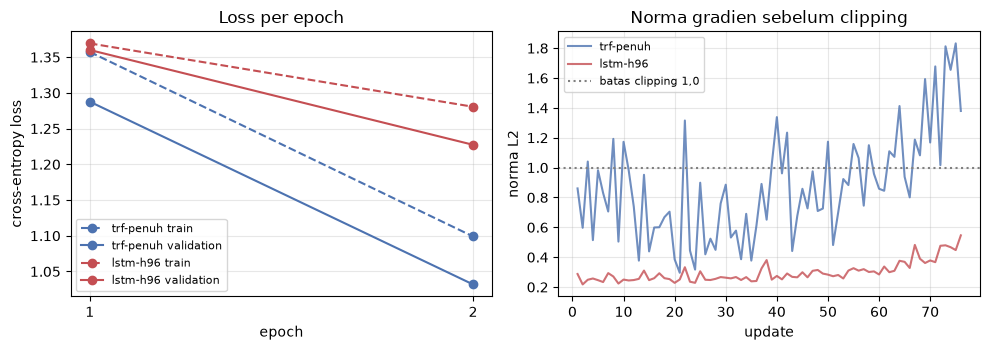

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
epoch = np.arange(1, EPOCHS + 1)
for nama, warna in zip(KONFIG_TERBIMBING, ['#4C72B0', '#C44E52']):
    hist = riwayat_terbimbing[nama]
    ax[0].plot(epoch, hist['train_loss'], marker='o', linestyle='--', color=warna, label=f'{nama} train')
    ax[0].plot(epoch, hist['val_loss'], marker='o', color=warna, label=f'{nama} validation')
    ax[1].plot(np.arange(1, len(hist['grad_norm']) + 1), hist['grad_norm'], color=warna,
               label=nama, alpha=0.8)
ax[0].set(title='Loss per epoch', xlabel='epoch', ylabel='cross-entropy loss', xticks=epoch)
ax[1].set(title='Norma gradien sebelum clipping', xlabel='update', ylabel='norma L2')
ax[1].axhline(1.0, color='gray', linestyle=':', label='batas clipping 1,0')
for a in ax:
    a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## G. Peta attention dan biaya panjang · Terbimbing

Peta memakai model `trf-penuh` terlatih dari bagian F. Contoh yang dipilih memiliki 12–30 token asli, tanpa sisa entitas HTML, dan dengan `<unk>` paling sedikit, sehingga seluruh peta $n\times n$ token asli terbaca.

contoh validasi #43, label 1, 21 token asli + 39 kolom bantalan
massa bobot ke bantalan: 0.00e+00 (harus nol)
tiga pasangan query -> key berbobot tertinggi (posisi dalam kurung):
  the (9) -> be (2): 0.200
  guards (17) -> against (19): 0.196
  starting (16) -> against (19): 0.176


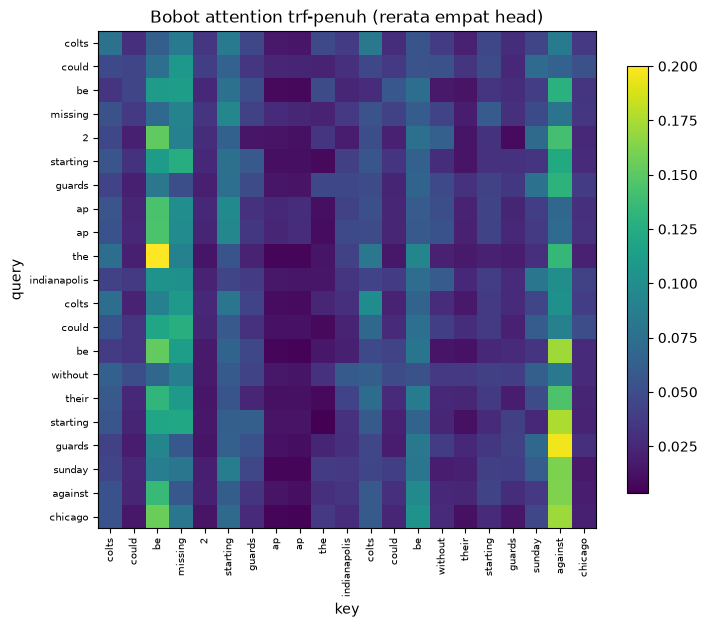

In [16]:
# Peta attention trf-penuh terlatih: need_weights=True, dengan mask bantalan.
model = simpan['trf-penuh'].to('cpu').eval()
# Contoh 12-30 token asli agar seluruh peta n x n terbaca; utamakan contoh tanpa sisa
# entitas HTML (&lt; &gt; &quot; &#39; &amp;) dan dengan <unk> paling sedikit.
ARTEFAK = {stoi[t] for t in ('lt', 'gt', 'quot', '39', 'amp') if t in stoi}
def urutan_contoh(j):
    t = X_val[j, :int(L_val[j])].tolist()
    return (bool(set(t) & ARTEFAK), t.count(1), j)
kandidat = [j for j in range(len(X_val)) if 12 <= int(L_val[j]) <= 30]
i = min(kandidat, key=urutan_contoh) if kandidat else int(L_val.argmax())
x, l = X_val[i:i + 1], int(L_val[i])
token = [itos[int(t)] for t in x[0, :l]]
with torch.no_grad():
    h = model.masukan(x)
    _, w = model.layer.self_attn(h, h, h, key_padding_mask=(x == 0),
                                 need_weights=True)

sisa = w[0, :l, l:].sum().item()
print(f'contoh validasi #{i}, label {y_val[i]}, {l} token asli + {x.size(1) - l} kolom bantalan')
print(f'massa bobot ke bantalan: {sisa:.2e} (harus nol)')
assert sisa < 1e-6
k = min(l, 30)
fig, ax = plt.subplots(figsize=(7.4, 6.4))
im = ax.imshow(w[0, :k, :k].numpy(), cmap='viridis')
ax.set_xticks(range(k)); ax.set_xticklabels(token[:k], rotation=90, fontsize=7)
ax.set_yticks(range(k)); ax.set_yticklabels(token[:k], fontsize=7)
ax.set_xlabel('key'); ax.set_ylabel('query')
ax.set_title('Bobot attention trf-penuh (rerata empat head)')
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.show()

datar = w[0, :l, :l].flatten()
pasangan = []                    # (query, key, bobot, posisi query, posisi key); pasangan token unik
for j in datar.argsort(descending=True).tolist():
    qi, ki = divmod(j, l)
    if (token[qi], token[ki]) not in [(p[0], p[1]) for p in pasangan]:
        pasangan.append((token[qi], token[ki], float(datar[j]), qi, ki))
    if len(pasangan) == 3:
        break
print('tiga pasangan query -> key berbobot tertinggi (posisi dalam kurung):')
for q, kk, bb, qi, ki in pasangan:
    print(f'  {q} ({qi}) -> {kk} ({ki}): {bb:.3f}')

**Dua pasangan token berbobot tertinggi.** Pasangan dan penilaiannya dibangun dari peta di atas. Kata fungsi (daftar stop word bahasa Inggris scikit-learn), sisa entitas HTML seperti `39` (dari `&#39;`) atau `quot`, dan token `<unk>` ditandai sebagai token tanpa isi topik; `ap`, `afp`, dan `reuters` ditandai sebagai tag kantor berita.

In [17]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

SUMBER = {'ap', 'afp', 'reuters'}                       # tag kantor berita, bukan bagian isi kalimat
TANPA_ISI = set(ENGLISH_STOP_WORDS) | {'<unk>', 's', "'s", '39', 'quot', 'lt', 'gt', 'amp', 'b', 'said'}

def jenis_pasangan(q, k, qi, ki):
    if qi == ki:
        return 'token memperhatikan dirinya sendiri; wajar pada satu layer, tetapi bukan relasi antarkata'
    if q == k:
        return (f'dua kemunculan token `{q}` yang sama saling memperhatikan; ini pencocokan identitas '
                'token, bukan relasi antarkata')
    if k in SUMBER:
        return (f'key `{k}` adalah tag kantor berita, bukan bagian isi kalimat; ini pola data AG News, '
                'bukan relasi linguistik')
    if k in TANPA_ISI:
        return f'key `{k}` tidak membawa isi topik; lebih mirip pola perhatian umum daripada relasi makna'
    if q in TANPA_ISI or q in SUMBER:
        return (f'query `{q}` tidak membawa isi topik, sedangkan key `{k}` kata isi; masuk akal sebagai '
                'aliran konteks ke token fungsi, bukan relasi antara dua kata bermakna')
    return (f'keduanya kata isi; masuk akal secara linguistik bila `{q}` dan `{k}` membentuk frasa '
            'atau menunjuk topik yang sama dalam kalimat ini')

display(Markdown('\n'.join(
    f'- `{q}` ({qi}) → `{k}` ({ki}), bobot {b:.3f}: {jenis_pasangan(q, k, qi, ki)}.'
    for q, k, b, qi, ki in pasangan[:2]
) + '\n\nBobot attention hanya menunjukkan ke mana informasi dialirkan pada satu layer ini, bukan '
    'penjelasan sebab-akibat prediksi. Pembuktian memerlukan ablasi, misalnya menghapus token lalu '
    'melihat perubahan logit.'))

- `the` (9) → `be` (2), bobot 0.200: key `be` tidak membawa isi topik; lebih mirip pola perhatian umum daripada relasi makna.
- `guards` (17) → `against` (19), bobot 0.196: key `against` tidak membawa isi topik; lebih mirip pola perhatian umum daripada relasi makna.

Bobot attention hanya menunjukkan ke mana informasi dialirkan pada satu layer ini, bukan penjelasan sebab-akibat prediksi. Pembuktian memerlukan ablasi, misalnya menghapus token lalu melihat perubahan logit.

In [18]:
# Waktu satu forward pass (batch 64, tanpa bantalan) untuk n in (30, 60, 120);
# satu pemanggilan pemanasan, lalu median 30 ulangan (tahan terhadap lonjakan beban CPU).
@torch.no_grad()
def waktu_forward(model, n, ulang=30, batch=64):
    model = model.to(DEVICE).eval()
    g = torch.Generator().manual_seed(BASE_SEED)
    x = torch.randint(2, V, (batch, n), generator=g).to(DEVICE)
    l = torch.full((batch,), n, dtype=torch.long)
    model(x, l); sync_device()                     # pemanasan
    waktu = []
    for _ in range(ulang):
        mulai = time.perf_counter()
        model(x, l); sync_device()
        waktu.append(time.perf_counter() - mulai)
    return 1000 * float(np.median(waktu))

baris = []
for n_ in (30, 60, 120):
    baris.append({'n': n_,
                  'lstm_ms': waktu_forward(simpan['lstm-h96'], n_),
                  'transformer_ms': waktu_forward(simpan['trf-penuh'], n_)})
biaya = pd.DataFrame(baris)
biaya['rasio_lstm'] = biaya['lstm_ms'] / biaya['lstm_ms'].iloc[0]
biaya['rasio_trf'] = biaya['transformer_ms'] / biaya['transformer_ms'].iloc[0]
print(biaya.to_string(index=False))

  n  lstm_ms  transformer_ms  rasio_lstm  rasio_trf
 30  31.2682         25.5793      1.0000     1.0000
 60  29.5295         56.8453      0.9444     2.2223
120  52.3130        129.1810      1.6730     5.0502


## Latihan Mandiri di Lab

Tanpa melatih ulang, bentuk model dengan $`h\in\{1,2,4,10\}`$ pada $`d_{\text{model}}=100`$ yang tetap. Laporkan jumlah parameter keempatnya dan jelaskan mengapa angkanya sama. Kemudian ukur waktu satu forward pass untuk setiap $`h`$ dan tuliskan satu alasan yang dapat diuji atas perbedaannya.

Tuliskan prediksi, hasil, dan perbandingannya di `latihan-09.md`, lalu kumpulkan lewat tugas **Latihan Mandiri di Lab — Modul 09**.

**Prediksi:** TODO

In [19]:
# TODO: bentuk model untuk n_head in (1, 2, 4, 10) pada D_MODEL tetap, misalnya
#       TransformerClassifier(nhead=...), tanpa melatih ulang; tabelkan d_k dan
#       jumlah parameter layer. Jelaskan mengapa angkanya sama.
# TODO: ukur waktu satu forward pass untuk setiap n_head, misalnya dengan
#       waktu_forward(model, 60) dari bagian G, lalu tuliskan satu alasan yang
#       dapat diuji atas perbedaan waktunya.
raise NotImplementedError('Selesaikan latihan mandiri.')

NotImplementedError: Selesaikan latihan mandiri.

### Hasil dan perbandingan dengan prediksi

**Jawaban:** TODO

## H. Dua belas run multi-seed - 25 poin · Tugas Individu

In [ ]:
# TODO: ubah MODE_TUGAS = True pada sel setup, lalu jalankan dua belas run
#       (empat konfigurasi x tiga seed) dengan protokol penuh.
# `buat_loader`, `evaluasi`, `bangun`, dan `jalankan` sudah tersedia dari bagian F.

KONFIG = ['lstm-h96', 'trf-tanpa-posisi', 'trf-tanpa-mask', 'trf-penuh']
hasil, riwayat, simpan = [], {}, {}
for seed in SEEDS:
    for nama in KONFIG:
        print(f'Melatih {nama}, seed={seed} ...')
        mdl, hist, row = jalankan(nama, seed)
        hasil.append(row); riwayat[(nama, seed)] = hist; simpan[nama] = mdl

tabel = pd.DataFrame(hasil)
print(tabel[['run_id', 'encoder_head_parameters', 'total_parameters',
             'val_loss', 'val_accuracy', 'grad_norm_mean',
             'seconds_per_epoch']].to_string(index=False))
assert len(tabel) == len(KONFIG) * len(SEEDS)
assert tabel.groupby('seed')['n_updates'].nunique().max() == 1, \
    'seluruh konfigurasi harus memakai anggaran update yang sama'
if MODE_TUGAS:
    assert len(tabel) == 12, 'hasil pengumpulan wajib memuat dua belas run'

In [ ]:
# TODO 15: dua panel — validation accuracy dan validation loss per epoch
#   untuk keempat konfigurasi pada BASE_SEED. Beri label sumbu, legenda, grid.
raise NotImplementedError

In [ ]:
# TODO 16: ringkasan per konfigurasi berisi acc_mean, acc_std (ddof=0),
#   seconds_mean, encoder_head_parameters, total_parameters, dan model_mib.
#   Buat bar chart acc_mean dengan error bar satu simpangan baku dan
#   anotasi waktu per epoch. Simpan tabelnya sebagai `ringkasan`.
raise NotImplementedError

In [ ]:
# TODO 19: simpan seluruh run ke metrics.csv.
if MODE_TUGAS:
    tabel.insert(1, 'student_id', NIM)
    output = Path(f'M09_{NIM}_metrics.csv')
    tabel.to_csv(output, index=False)
    print(f'{len(tabel)} baris disimpan ke {output}')
else:
    print('MODE_TUGAS masih False; metrics.csv belum ditulis.')

## I. Pertanyaan analisis dan keputusan - 10 poin · Tugas Individu

1. Berapa selisih akurasi Transformer penuh terhadap LSTM, dan apakah lebih
   besar daripada variasi antar-seed? **TODO**
2. Berapa penurunan akurasi akibat mematikan penyandian posisi, dan bagaimana
   kaitannya dengan probe permutasi? **TODO**
3. Berapa penurunan akurasi akibat mematikan mask, dan mengapa kesalahan ini
   tidak menimbulkan pesan galat? **TODO**
4. Arsitektur mana yang lebih cepat pada $n=60$, dan bagaimana urutannya pada
   $n=120$? Kaitkan dengan $O(n)$ lawan $O(n^2)$ memakai angka sendiri. **TODO**
5. Jika model harus melayani teks jauh lebih panjang dengan batas memori tetap,
   arsitektur mana yang Anda pilih? Gunakan sedikitnya tiga angka. **TODO**

## Checklist sebelum mengumpulkan

- [ ] Identitas terisi dan `MODE_TUGAS=True`.
- [ ] Attention buatan sendiri cocok dengan PyTorch di bawah $10^{-5}$.
- [ ] Empat angka entropi dilaporkan terhadap $\log 64$.
- [ ] Ketiga probe dijalankan pada model belum terlatih dan berupa angka.
- [ ] Selisih anggaran encoder + head terhadap LSTM tidak lebih dari 1%.
- [ ] Dua belas run tercatat, termasuk kedua ablasi yang benar-benar dilatih.
- [ ] Norma gradien dicatat sebelum clipping.
- [ ] Peta attention memperlihatkan kolom bantalan bernilai nol.
- [ ] Waktu forward pass diukur untuk $n \in \{30, 60, 120\}$.
- [ ] Test set tidak dipakai untuk tuning atau pemilihan model.
- [ ] `metrics.csv` memuat seluruh run.
- [ ] Notebook lolos *Restart Kernel and Run All*.